# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

--- First 5 Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. There are a few bookings that have very long lead times compared to the others. The maximum is 700 days, which is unusual. As well, there is zero guest bookings, where really doesn't make sense for a valid hotel booking.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

Original dataset shape: (9404, 32)
Cleaned and scaled dataset shape: (6236, 4)

First few rows of the scaled features:


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
2,-0.861172,-1.146695,-0.994214,-0.389410
3,-0.773746,-1.146695,-0.994214,-0.389410
4,-0.759175,-1.146695,-0.583188,0.049700
6,-0.963169,-1.146695,-0.583188,0.221526
7,-0.832030,-1.146695,-0.583188,0.145159


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected the lead time, stays on the weekend, ADR, and stays on the weekdays. I feel like these are the most important part of the data because property owners need to know the amount of days/nights for the guests to accomadate them. They also have relatively similar scaled data points.

2. The weekend travelers, long-stay vacationers, business travelers, or budget travelers.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

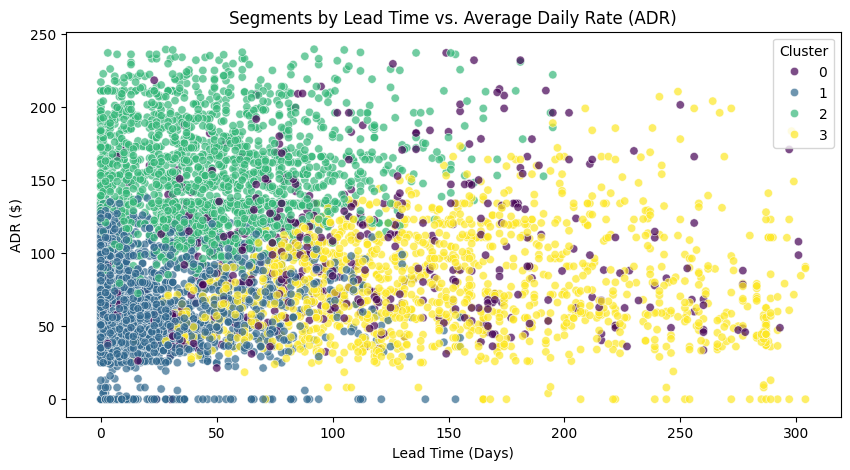

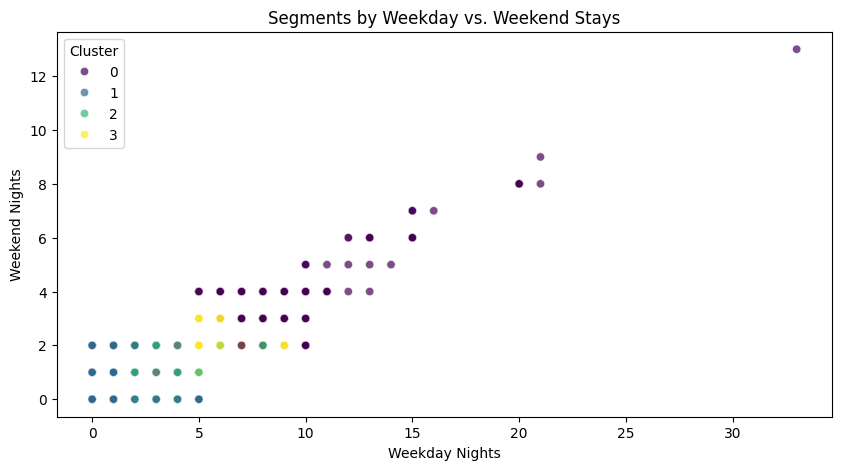

--- Cluster Summary Table (Averages) ---


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,count
cluster,,,,,
0,108.577253,3.731760,8.703863,98.742768,466
1,21.666531,0.617384,1.766450,60.411653,2462
2,49.747835,1.290043,3.494589,155.360043,1848
3,148.176712,1.710274,4.422603,77.425568,1460


### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose four clusters. I chose it since it isolates the weekenders, weekdays, early planners, and budget travelers into their own segments. This makes the data a lot easier to read.

2. The long term stayers who average one week + on their stays, budget guests (who book close to arrival and pay the least amount), premium guests (those who book the highest rates/high ADR), and early-bird planners (people who book the furthest in advance to get the best deal).


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

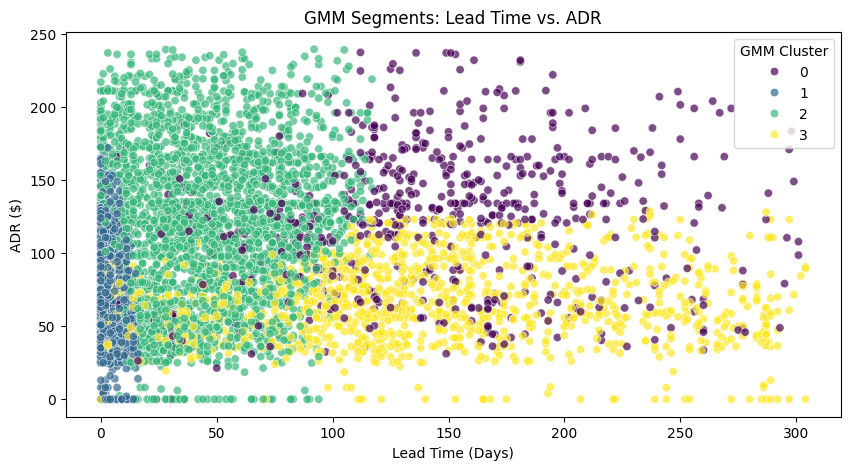

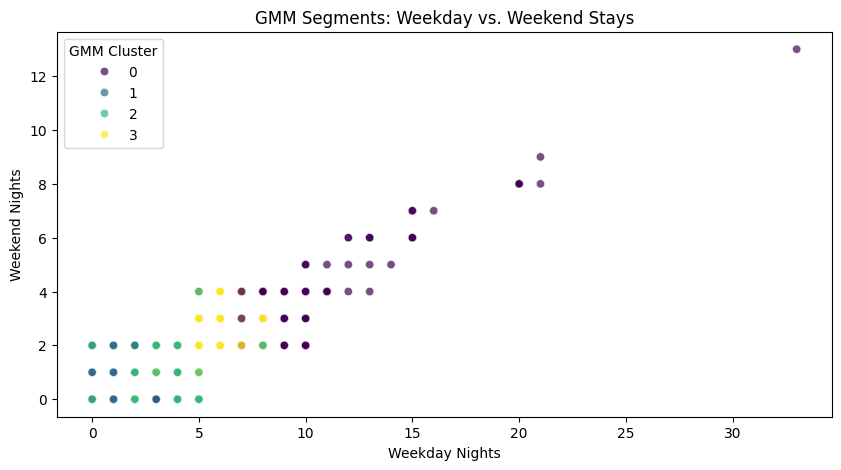

--- GMM Cluster Summary Table (Averages) ---


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,count
gmm_cluster,,,,,
0,141.094400,2.747200,7.297600,122.290720,625
1,4.159204,0.523810,1.253731,63.524328,1407
2,46.766807,1.162815,3.172969,119.369265,2856
3,136.951039,1.754451,4.401335,65.404496,1348


In [8]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(df_scaled[features])

soft_probs = gmm.predict_proba(df_scaled[features])

prep_df['gmm_cluster'] = gmm.predict(df_scaled[features])

for i in range(4):
    prep_df[f'prob_cluster_{i}'] = soft_probs[:, i]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=prep_df, x='lead_time', y='adr', hue='gmm_cluster', palette='viridis', alpha=0.7)
plt.title('GMM Segments: Lead Time vs. ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('ADR ($)')
plt.legend(title='GMM Cluster')
plt.show()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=prep_df, x='stays_in_week_nights', y='stays_in_weekend_nights', hue='gmm_cluster', palette='viridis', alpha=0.7)
plt.title('GMM Segments: Weekday vs. Weekend Stays')
plt.xlabel('Weekday Nights')
plt.ylabel('Weekend Nights')
plt.legend(title='GMM Cluster')
plt.show()

gmm_summary = prep_df.groupby('gmm_cluster')[features].mean()
gmm_summary['count'] = prep_df.groupby('gmm_cluster').size()

print("--- GMM Cluster Summary Table (Averages) ---")
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1.KMeans assigns every guest to one group, where GMM allows overlaps on the data, calculating the probability of a guest belonging to each group.

2. "What customers have mixed behavior?" Or "How sure are we about this guest's segment?"


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [9]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

kmeans_model = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans_model.fit_predict(scaled_features)

gmm_model = GaussianMixture(n_components=4, random_state=42)
gmm_labels = gmm_model.fit_predict(scaled_features)

kmeans_wcss = kmeans_model.inertia_
kmeans_silhouette = silhouette_score(scaled_features, kmeans_labels)
kmeans_db = davies_bouldin_score(scaled_features, kmeans_labels)

gmm_silhouette = silhouette_score(scaled_features, gmm_labels)
gmm_db = davies_bouldin_score(scaled_features, gmm_labels)

print("=== K-Means Metrics ===")
print(f"WCSS (Inertia): {kmeans_wcss:.4f}")
print(f"Silhouette Score: {kmeans_silhouette:.4f}")
print(f"Davies-Bouldin Index: {kmeans_db:.4f}")
print()
print("=== GMM Metrics ===")
print(f"Silhouette Score: {gmm_silhouette:.4f}")
print(f"Davies-Bouldin Index: {gmm_db:.4f}")

=== K-Means Metrics ===
WCSS (Inertia): 11059.7834
Silhouette Score: 0.3101
Davies-Bouldin Index: 1.1851

=== GMM Metrics ===
Silhouette Score: 0.1497
Davies-Bouldin Index: 1.7393


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2 - KMeans.

5.3 - I would recommend KMeans because it is a lot easier and faster to run, and produces clear boundaries so that marketing campaigns are accurate towards the desired group(s).


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [10]:
prep_df['kmeans_cluster'] = kmeans_labels

features_to_show = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr']

kmeans_profile = prep_df.groupby('kmeans_cluster')[features_to_show].mean().sort_values(by='lead_time')

print("=== Profiling K-Means Clusters (Sorted by Lead Time) ===")
display(kmeans_profile)

prep_df['gmm_cluster'] = gmm_labels
gmm_profile = prep_df.groupby('gmm_cluster')[features_to_show].mean().sort_values(by='lead_time')

print("\n=== Profiling GMM Clusters (Sorted by Lead Time) ===")
display(gmm_profile)

=== Profiling K-Means Clusters (Sorted by Lead Time) ===


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
kmeans_cluster,,,,
1,21.666531,0.617384,1.766450,60.411653
2,49.747835,1.290043,3.494589,155.360043
0,108.577253,3.731760,8.703863,98.742768
3,148.176712,1.710274,4.422603,77.425568



=== Profiling GMM Clusters (Sorted by Lead Time) ===


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr
gmm_cluster,,,,
1,4.159204,0.523810,1.253731,63.524328
2,46.766807,1.162815,3.172969,119.369265
3,136.951039,1.754451,4.401335,65.404496
0,141.094400,2.747200,7.297600,122.290720


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 1 - last minute bookings, cluster 2 - short stayers, cluster 0 - long-term planners, cluster 3 - early-bird planners.

2. For cluster 1 - offering quick, impulse booking discounts, cluster 2 - luxury add on offerings, cluster 0 - offer extended-stay discounts, cluster 3 - send early booking incentives or discounts.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The hardest part is that there are no right or wrong answers or labels to check your work against. This means you have to rely on statistics and your own business sense to guess if the groups you found are actually useful.

2. You use clustering when your data doesn't have any labels, targets, or past outcomes to train a model with. It is ideal for exploring your data from scratch to find natural, hidden groups of your customers.

3. Clustering is like sorting a huge, messy pile of random stuff and turning it into organized piles. Instead of trying to create thousands of different plans for every single individual customer, clustering lets us group similar customers together.

4. This project proves how we can use data grouping methods to make smart, real-world business decisions that improve customer marketing and sales, which is exactly what I stated in my customized learning outcome of what I wanted to get out of this course.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [11]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 1427420 bytes to assignment_09_clustering.html
